# Day-ahead demand forecast with legitimate lags (Phase 3, step 3b)

**What this notebook does.** It forecasts how many Uber/Lyft requests each of the 263 NYC taxi zones gets in each clock hour (our stand-in for robotaxi demand), using only information that is known at least **7 days** before the forecast hour.

**Why it exists.** The first forecast (`03_forecast.ipynb`) removed *all* demand history because the last hour's final counts may not be known yet. That was too strict. The demand from exactly 7, 14, 21 and 28 days earlier (same zone, same weekday, same clock hour) is always known a week ahead, so a dispatcher can use it when planning a day in advance. A frozen August profile scored MAE 22.5 on November-December; a plain average of the previous four same-weekday-hour weeks scored about 19.2.

**Terms.** *Lag* = the count from the same zone and clock hour 7 / 14 / 21 / 28 days earlier. *MAE* = average absolute error in requests per zone-hour. *WAPE* = total absolute error divided by total actual requests (a percentage). *Gradient boosting* = many small decision trees added one after another, each fixing the mistakes of the ones before.

**Research rules kept.** Train January-August 2024, tune on September, set a count-bias scale on 1-15 October, choose the final method on 16-31 October. The choice is saved to disk **before** any November-December count is read. November-December was already inspected in an older experiment, so its scores are labelled *previously examined, not a pristine test*. January 2025 gets predictions only (for the later drift check) and is never scored or used for fitting.

**Last full run:** see the final cell, which prints the run time.

## Step 1. Set up: paths, settings and constants

All dates, seeds and model settings are named constants in this one cell, so nothing is hidden further down. The repository root is found by walking up to the folder that holds `repo_instructions.md`, so no personal path is typed in.

In [1]:
import sys
from pathlib import Path

REPO_ROOT = next((folder for folder in [Path.cwd(), *Path.cwd().parents]
                  if (folder / "repo_instructions.md").is_file()), None)
if REPO_ROOT is None:
    raise FileNotFoundError("Run this notebook from inside the repository.")
sys.path.insert(0, str(REPO_ROOT))

In [2]:
import json
import warnings
from datetime import UTC, datetime
from importlib import metadata

import duckdb
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance

from src.demand_features import (
    CIVIL_KEY,
    LAG_COLUMNS,
    add_baseline_columns,
    build_features,
    build_frozen_profiles,
    fit_count_scale,
    list_feature_columns,
    make_civil_hour_table,
    mark_common_rows,
    score_by_group,
    score_forecast,
)

# Two harmless library warnings (DuckDB uses an old pandas keyword; tqdm wants ipywidgets).
warnings.filterwarnings("ignore", message=".*inplace keyword.*")
warnings.filterwarnings("ignore", message=".*IProgress.*")
RUN_STARTED_UTC = datetime.now(UTC)
RANDOM_SEED = 20261115
TRAIN_START = "2024-01-01"
TRAIN_END = "2024-09-01"            # train = Jan-Aug (end date not included)
TUNING_END = "2024-10-01"           # tuning = September
CALIBRATION_END = "2024-10-16"      # count-bias scale = 1-15 October
SELECTION_END = "2024-11-01"        # final choice = 16-31 October
TEST_END = "2025-01-01"             # test = Nov-Dec (previously examined)
FORECAST_START = "2024-10-01"       # forecast file starts here
DRIFT_END = "2025-02-01"            # January 2025 is predicted for later drift use
SHAP_SAMPLE_ROWS = 5000
PERMUTATION_REPEATS = 3
QUARTILE_LABELS = ["Low", "Lower-middle", "Upper-middle", "High"]
RELEASE_DIR = REPO_ROOT / "data/releases/phase1-2024-v1"
FORECAST_DIR = REPO_ROOT / "data/forecasts"
FORECAST_DIR.mkdir(parents=True, exist_ok=True)

BASELINE_COLUMNS = ["pred_last_week", "pred_four_week_mean", "pred_frozen_profile", "pred_frozen_profile_7d"]
BASELINE_NAMES = {
    "pred_last_week": "Last week (lag_7d)",
    "pred_four_week_mean": "Mean of previous 4 weeks",
    "pred_frozen_profile": "Frozen 28-day profile (Krish)",
    "pred_frozen_profile_7d": "Frozen 7-day profile (Krish)",
}

# Four small candidate settings, written down before any score was seen.
CANDIDATE_SETTINGS = {
    "hgb_squared_small": {"loss": "squared_error", "learning_rate": 0.1, "max_iter": 200,
                          "max_leaf_nodes": 15, "min_samples_leaf": 200},
    "hgb_squared_large": {"loss": "squared_error", "learning_rate": 0.05, "max_iter": 400,
                          "max_leaf_nodes": 31, "min_samples_leaf": 100},
    "hgb_poisson_small": {"loss": "poisson", "learning_rate": 0.1, "max_iter": 200,
                          "max_leaf_nodes": 15, "min_samples_leaf": 200},
    "hgb_poisson_large": {"loss": "poisson", "learning_rate": 0.05, "max_iter": 400,
                          "max_leaf_nodes": 31, "min_samples_leaf": 100},
}
plt.rcParams.update({"figure.dpi": 100, "axes.spines.right": False, "axes.spines.top": False})
print("Repository root found; forecast outputs go to", FORECAST_DIR.relative_to(REPO_ROOT))

Repository root found; forecast outputs go to data\forecasts


## Step 2. Load January-October only (train and validation)

We read the Phase 1 hourly table with DuckDB (pyarrow is blocked on this machine). At this stage we load **only the train and validation periods**; November-December labels are not read until the final choice is saved. We also load the zone table (borough, centroid, airport flag). `request_count` is null when coverage was incomplete; we never turn a null into zero.

In [3]:
table_index = json.loads((RELEASE_DIR / "metadata/table_index.json").read_text(encoding="utf-8"))
zone_hour_path = REPO_ROOT / table_index["zone_hour"]["path"]
zones_path = REPO_ROOT / table_index["zones"]["path"]
ZONE_HOUR_COLUMNS = ("zone_id, hour_start_utc, event_date_nyc, hour_nyc, period_label, "
                     "request_count, is_federal_holiday")
connection = duckdb.connect()


def read_zone_hours(period_labels):
    """Read the hourly zone table for the given period labels (train, validation, ...)."""
    label_list = ", ".join(f"'{label}'" for label in period_labels)
    query = (f"select {ZONE_HOUR_COLUMNS} from read_parquet('{zone_hour_path}/**/*.parquet', "
             f"hive_partitioning=true) where period_label in ({label_list})")
    rows = connection.execute(query).df()
    print(f"Read {len(rows):,} zone-hour rows for {period_labels}")
    return rows


pretest_rows = read_zone_hours(["train", "validation"])
zones = connection.execute(
    f"select zone_id, borough, is_airport, centroid_latitude, centroid_longitude "
    f"from read_parquet('{zones_path}/**/*.parquet')").df()
BOROUGHS = sorted(zones["borough"].unique())
print("Zones:", len(zones), "| boroughs:", BOROUGHS)
print("Latest day loaded:", pretest_rows["event_date_nyc"].max().date())
print("Null request counts in train+validation:", int(pretest_rows["request_count"].isna().sum()))
assert pretest_rows["event_date_nyc"].max() < pd.Timestamp(SELECTION_END)
assert len(zones) == 263 and zones["zone_id"].is_unique

Read 1,924,897 zone-hour rows for ['train', 'validation']
Zones: 263 | boroughs: ['Bronx', 'Brooklyn', 'EWR', 'Manhattan', 'Queens', 'Staten Island']
Latest day loaded: 2024-10-31
Null request counts in train+validation: 0


## Step 3. Civil-time key and lag features

Lags are defined on **New York civil time**: "same weekday and same clock hour, 7 days earlier". We therefore key every row by `(zone_id, event_date_nyc, hour_nyc)`. On the autumn clock-change day the clock hour 1 happens twice; those two rows share one civil key, so they are averaged (and stay null if either count is null). Then `build_features` adds the calendar inputs, zone geography, the four lags, their mean (only when at least 2 lags exist) and a ratio of last week to that mean. No weather, fares or any other outcome is used.

In [4]:
civil_pretest = make_civil_hour_table(pretest_rows)
features_pretest = build_features(civil_pretest, zones, BOROUGHS)
frozen_profiles = build_frozen_profiles(civil_pretest, TRAIN_END)
table_pretest = add_baseline_columns(features_pretest, frozen_profiles)
table_pretest["is_common_row"] = mark_common_rows(table_pretest, BASELINE_COLUMNS)
FEATURE_COLUMNS = list_feature_columns(BOROUGHS)
print("Number of model inputs:", len(FEATURE_COLUMNS))
print(FEATURE_COLUMNS)
display(table_pretest[["zone_id", "event_date_nyc", "hour_nyc", "request_count", *LAG_COLUMNS,
                       "lag_mean_4w", "pred_frozen_profile"]].iloc[2000:2005])

Civil hour table: 1,924,897 zone-hour rows -> 1,924,897 civil rows


Lag features added: 1,924,897 rows


Geography added: 1,924,897 rows


Baselines added: 1,924,897 rows
Number of model inputs: 28
['hour', 'weekday', 'month', 'is_weekend', 'is_federal_holiday', 'hour_sin', 'hour_cos', 'weekday_sin', 'weekday_cos', 'centroid_latitude', 'centroid_longitude', 'is_airport', 'borough_Bronx', 'borough_Brooklyn', 'borough_EWR', 'borough_Manhattan', 'borough_Queens', 'borough_Staten Island', 'lag_7d', 'lag_14d', 'lag_21d', 'lag_28d', 'lag_7d_is_holiday', 'lag_14d_is_holiday', 'lag_21d_is_holiday', 'lag_28d_is_holiday', 'lag_mean_4w', 'lag_7d_ratio']


,zone_id,event_date_nyc,hour_nyc,request_count,lag_7d,lag_14d,lag_21d,lag_28d,lag_mean_4w,pred_frozen_profile
2000,1,2024-03-24,9,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2001,1,2024-03-24,10,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2002,1,2024-03-24,11,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2003,1,2024-03-24,12,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2004,1,2024-03-24,13,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## Step 4. Which rows can be scored?

To compare methods fairly, every method is scored on the **identical rows**: rows that have an actual count and where *all* baselines can make a forecast (all four lags present, and both frozen profiles present). The table shows how many rows each period has and how many are lost for each reason. The model itself can still forecast rows with missing lags (it handles missing values natively); those rows are reported separately later.

In [5]:
PERIODS = {
    "train (Jan-Aug)": (TRAIN_START, TRAIN_END),
    "tuning (Sep)": (TRAIN_END, TUNING_END),
    "scale fit (Oct 1-15)": (TUNING_END, CALIBRATION_END),
    "selection (Oct 16-31)": (CALIBRATION_END, SELECTION_END),
}


def select_dates(table, start, end):
    """Return a yes/no mask for rows whose New York date is in [start, end)."""
    return (table["event_date_nyc"] >= pd.Timestamp(start)) & (table["event_date_nyc"] < pd.Timestamp(end))


coverage_rows = []
for period_name, (start, end) in PERIODS.items():
    period_rows = table_pretest[select_dates(table_pretest, start, end)]
    coverage_rows.append({
        "period": period_name,
        "all_rows": len(period_rows),
        "actual_known": int(period_rows["request_count"].notna().sum()),
        "all_4_lags_known": int(period_rows[LAG_COLUMNS].notna().all(axis=1).sum()),
        "common_rows_scored": int(period_rows["is_common_row"].sum()),
    })
display(pd.DataFrame(coverage_rows).set_index("period"))

,all_rows,actual_known,all_4_lags_known,common_rows_scored
period,,,,
train (Jan-Aug),1539865,1539865,1362077,1362077
tuning (Sep),189360,189360,189360,189360
scale fit (Oct 1-15),94680,94680,94680,94680
selection (Oct 16-31),100992,100992,100992,100992


## Step 5. Fit four gradient-boosting candidates on January-August; choose on September only

`HistGradientBoostingRegressor` is scikit-learn's fast gradient boosting. It accepts missing lags directly, so rows from the first weeks of January (when lags do not exist yet) stay in training. Early stopping is switched off and the random seed is fixed, so a rerun gives the same model. The four candidates differ in loss (squared error versus Poisson, which suits counts) and size. **Only September decides** which candidate is kept.

In [6]:
def fit_candidate(settings, training_table):
    """Fit one gradient boosting model on the training rows and return it."""
    model = HistGradientBoostingRegressor(early_stopping=False, random_state=RANDOM_SEED, **settings)
    return model.fit(training_table[FEATURE_COLUMNS], training_table["request_count"])


def predict_counts(model, table):
    """Predict requests per zone-hour and clip impossible negative values to zero."""
    return np.maximum(model.predict(table[FEATURE_COLUMNS]), 0.0)


train_rows = table_pretest[select_dates(table_pretest, TRAIN_START, TRAIN_END)
                           & table_pretest["request_count"].notna()]
tuning_rows = table_pretest[select_dates(table_pretest, TRAIN_END, TUNING_END) & table_pretest["is_common_row"]]
print(f"Training rows: {len(train_rows):,} | September scoring rows: {len(tuning_rows):,}")

candidate_models = {}
tuning_records = []
for candidate_name, settings in CANDIDATE_SETTINGS.items():
    candidate_models[candidate_name] = fit_candidate(settings, train_rows)
    september_scores = score_forecast(tuning_rows["request_count"], predict_counts(candidate_models[candidate_name], tuning_rows))
    tuning_records.append({"candidate": candidate_name, **september_scores})
tuning_table = pd.DataFrame(tuning_records).set_index("candidate").sort_values(["MAE", "WAPE_percent"])
display(tuning_table)
best_candidate = tuning_table.index[0]
frozen_model = candidate_models[best_candidate]
print("September choice:", best_candidate)

Training rows: 1,539,865 | September scoring rows: 189,360


,rows,MAE,RMSE,WAPE_percent
candidate,,,,
hgb_squared_small,189360,15.005405,30.167332,14.943872
hgb_squared_large,189360,15.036525,30.280177,14.974866
hgb_poisson_large,189360,15.054970,30.404512,14.993234
hgb_poisson_small,189360,15.097630,30.447193,15.035720


September choice: hgb_squared_small


## Step 6. Count-bias scale on 1-15 October, then the final choice on 16-31 October

Tree models tend to under-predict when demand drifts upward after the training months. A single global **count-bias scale** = (total actual requests) / (total predicted requests) is fitted on 1-15 October only. It is a simple multiplier, not a new model. Then 16-31 October compares: the model raw, the model scaled, and the four baselines, all on identical rows. The method with the lowest MAE wins (WAPE breaks ties).

Count-bias scale fitted on Oct 1-15 (94,680 rows): 1.0213


,rows,MAE,RMSE,WAPE_percent
Mean of previous 4 weeks,100992.0,12.520063,26.345725,12.078269
"Model, scaled",100992.0,12.802652,27.497289,12.350886
"Model, raw",100992.0,13.209443,28.495868,12.743322
Last week (lag_7d),100992.0,14.969710,30.691323,14.441475
Frozen 28-day profile (Krish),100992.0,17.112103,35.322708,16.508269
Frozen 7-day profile (Krish),100992.0,20.416696,42.193291,19.696254


Frozen choice among all methods: Mean of previous 4 weeks | scale used for pred_model: True


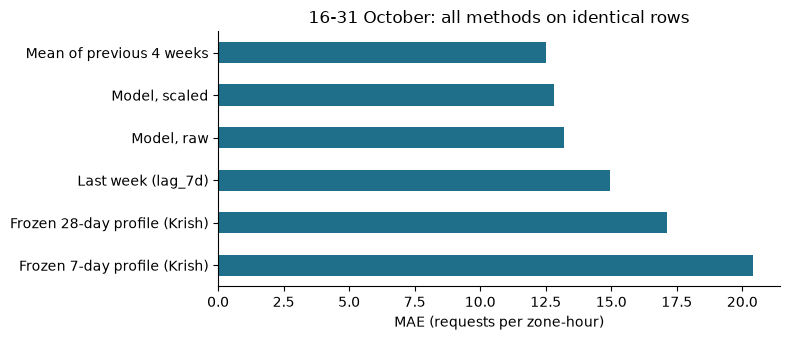

In [7]:
calibration_rows = table_pretest[select_dates(table_pretest, TUNING_END, CALIBRATION_END) & table_pretest["is_common_row"]]
selection_rows = table_pretest[select_dates(table_pretest, CALIBRATION_END, SELECTION_END) & table_pretest["is_common_row"]]
count_scale = fit_count_scale(calibration_rows["request_count"], predict_counts(frozen_model, calibration_rows))
print(f"Count-bias scale fitted on Oct 1-15 ({len(calibration_rows):,} rows): {count_scale:.4f}")

raw_selection_prediction = predict_counts(frozen_model, selection_rows)
selection_predictions = {
    "Model, raw": raw_selection_prediction,
    "Model, scaled": raw_selection_prediction * count_scale,
}
for column, name in BASELINE_NAMES.items():
    selection_predictions[name] = selection_rows[column].to_numpy()
selection_table = pd.DataFrame({name: score_forecast(selection_rows["request_count"], prediction)
                                for name, prediction in selection_predictions.items()}).T
selection_table = selection_table.sort_values(["MAE", "WAPE_percent"])
display(selection_table)
final_method = selection_table.index[0]
use_scale = bool(selection_table.loc["Model, scaled", "MAE"] < selection_table.loc["Model, raw", "MAE"])
if final_method.startswith("Model"):
    final_method_column = "pred_model"
else:
    final_method_column = next(column for column, name in BASELINE_NAMES.items() if name == final_method)
print("Frozen choice among all methods:", final_method, "| scale used for pred_model:", use_scale)

fig, axis = plt.subplots(figsize=(8, 3.5))
selection_table["MAE"].sort_values(ascending=False).plot.barh(ax=axis, color="#1f6f8b")
axis.set(xlabel="MAE (requests per zone-hour)", ylabel="", title="16-31 October: all methods on identical rows")
plt.tight_layout()
plt.show()

## Step 7. Save the frozen choice **before** reading November-December

From here nothing about the model changes. The chosen settings, scale, seeds and the date windows are written to `data/forecasts/frozen_choice.json`, and the fitted model is saved. Only after this file exists does the notebook load the test and drift periods.

In [8]:
frozen_choice = {
    "saved_at_utc": datetime.now(UTC).isoformat(),
    "nov_dec_labels_read_before_this_file_was_saved": False,
    "random_seed": RANDOM_SEED,
    "windows": {"train": [TRAIN_START, TRAIN_END], "tuning_september": [TRAIN_END, TUNING_END],
                "scale_fit_oct_1_15": [TUNING_END, CALIBRATION_END],
                "selection_oct_16_31": [CALIBRATION_END, SELECTION_END],
                "test_nov_dec_previously_examined": [SELECTION_END, TEST_END]},
    "candidate_settings": CANDIDATE_SETTINGS,
    "september_scores": tuning_table.reset_index().to_dict(orient="records"),
    "chosen_candidate": best_candidate,
    "chosen_settings": CANDIDATE_SETTINGS[best_candidate],
    "count_bias_scale": count_scale,
    "pred_model_uses_scale": use_scale,
    "selection_scores_oct_16_31": selection_table.reset_index(names="method").to_dict(orient="records"),
    "best_method_on_oct_16_31": final_method,
    "best_method_column_in_forecast_file": final_method_column,
    "feature_columns": FEATURE_COLUMNS,
    "frozen_profile_end_date": TRAIN_END,
}
choice_path = FORECAST_DIR / "frozen_choice.json"
choice_path.write_text(json.dumps(frozen_choice, indent=2), encoding="utf-8")
joblib.dump(frozen_model, FORECAST_DIR / "frozen_model.joblib")
print("Saved", choice_path.relative_to(REPO_ROOT), "and frozen_model.joblib")

Saved data\forecasts\frozen_choice.json and frozen_model.joblib


## Step 8. Load November-December and January 2025; rebuild features on the full table

Now the later periods are read. Their counts serve two purposes: (a) labels for scoring November-December, and (b) lag inputs for target hours at least 7 days later (a count from 1 November is a legitimate lag for 8 November). January 2025 is used for predictions only. As a safety check we confirm that adding later months did not change a single feature value of the 16-31 October rows, which shows that lags only look backwards.

In [9]:
later_rows = read_zone_hours(["test", "drift"])
all_rows = pd.concat([pretest_rows, later_rows], ignore_index=True)
print(f"All zone-hour rows: {len(all_rows):,}")
civil_all = make_civil_hour_table(all_rows)
features_all = build_features(civil_all, zones, BOROUGHS)
profiles_all = build_frozen_profiles(civil_all, TRAIN_END)
pd.testing.assert_frame_equal(frozen_profiles, profiles_all)
table_all = add_baseline_columns(features_all, profiles_all)
table_all["is_common_row"] = mark_common_rows(table_all, BASELINE_COLUMNS)

october_late_before = table_pretest[select_dates(table_pretest, CALIBRATION_END, SELECTION_END)]
october_late_after = table_all[select_dates(table_all, CALIBRATION_END, SELECTION_END)]
pd.testing.assert_frame_equal(october_late_before[CIVIL_KEY + FEATURE_COLUMNS].reset_index(drop=True),
                              october_late_after[CIVIL_KEY + FEATURE_COLUMNS].reset_index(drop=True))
print("PASS: later months did not change any earlier feature (lags only look back).")

Read 580,967 zone-hour rows for ['test', 'drift']
All zone-hour rows: 2,505,864


Civil hour table: 2,505,864 zone-hour rows -> 2,505,601 civil rows


Lag features added: 2,505,601 rows


Geography added: 2,505,601 rows


Baselines added: 2,505,601 rows
PASS: later months did not change any earlier feature (lags only look back).


## Step 9. Predict every zone-hour from 1 October 2024 to 31 January 2025

The frozen model is applied to all rows from 1 October on, with the scale only if it was chosen. The three baselines and both frozen profiles come from the same feature table. Predictions are one per civil key; the repeated clock-change hour gets the same prediction for both of its real UTC hours.

In [10]:
forecast_table = table_all[select_dates(table_all, FORECAST_START, DRIFT_END)].copy()
forecast_table["pred_model_raw"] = predict_counts(frozen_model, forecast_table)
forecast_table["pred_model"] = forecast_table["pred_model_raw"] * (count_scale if use_scale else 1.0)
forecast_table["is_scored_row"] = forecast_table["is_common_row"]
print(f"Forecast rows (civil keys): {len(forecast_table):,}")
print(forecast_table.groupby("period_label")["is_scored_row"].agg(["size", "sum"]))

Forecast rows (civil keys): 776,376
                size     sum
period_label                
drift         195672  195672
test          385032  383717
validation    195672  195672


## Step 10. Score November-December (previously examined period, not a pristine test)

All methods are scored on the **identical rows** (actual known, four lags known, frozen profiles known). The frozen model and the choice among methods were fixed in Step 7 and are not changed after seeing these numbers. MAE and RMSE are in requests per zone-hour; WAPE is a percentage.

Nov-Dec rows: 385,032 | actual known: 384,769 | identical scored rows: 383,717
PREVIOUSLY EXAMINED PERIOD - not a pristine test


,rows,MAE,RMSE,WAPE_percent
Frozen model (HGB),383717,18.933150,39.575813,17.986277
Model without scale,383717,19.072488,39.635308,18.118647
Last week (lag_7d),383717,23.107360,49.439793,21.951729
Mean of previous 4 weeks,383717,19.213401,40.898773,18.252512
Frozen 28-day profile (Krish),383717,22.507717,45.041509,21.382075
Frozen 7-day profile (Krish),383717,25.185238,50.312023,23.925690


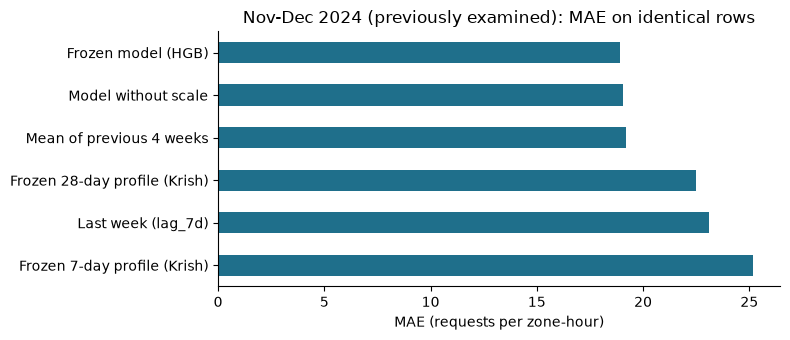

Method frozen on 16-31 October: Mean of previous 4 weeks -> Nov-Dec MAE 19.213 (frozen model: 18.933)
The model can also forecast rows lacking some lags: 1,052 extra rows; MAE on all 384,769 rows with a known actual = 18.963


In [11]:
METHOD_COLUMNS = {
    "pred_model": "Frozen model (HGB)",
    "pred_model_raw": "Model without scale",
    "pred_last_week": BASELINE_NAMES["pred_last_week"],
    "pred_four_week_mean": BASELINE_NAMES["pred_four_week_mean"],
    "pred_frozen_profile": BASELINE_NAMES["pred_frozen_profile"],
    "pred_frozen_profile_7d": BASELINE_NAMES["pred_frozen_profile_7d"],
}
test_rows = forecast_table[select_dates(forecast_table, SELECTION_END, TEST_END)]
test_scored = test_rows[test_rows["is_scored_row"]].copy()
print(f"Nov-Dec rows: {len(test_rows):,} | actual known: {int(test_rows['request_count'].notna().sum()):,} "
      f"| identical scored rows: {len(test_scored):,}")
overall_scores = pd.DataFrame({name: score_forecast(test_scored["request_count"], test_scored[column])
                               for column, name in METHOD_COLUMNS.items()}).T
overall_scores["rows"] = overall_scores["rows"].astype(int)
print("PREVIOUSLY EXAMINED PERIOD - not a pristine test")
display(overall_scores)

fig, axis = plt.subplots(figsize=(8, 3.5))
overall_scores["MAE"].sort_values(ascending=False).plot.barh(ax=axis, color="#1f6f8b")
axis.set(xlabel="MAE (requests per zone-hour)", ylabel="",
         title="Nov-Dec 2024 (previously examined): MAE on identical rows")
plt.tight_layout()
plt.show()

frozen_choice_mae = overall_scores.loc[METHOD_COLUMNS[final_method_column], "MAE"]
print(f"Method frozen on 16-31 October: {final_method} -> Nov-Dec MAE {frozen_choice_mae:.3f} "
      f"(frozen model: {overall_scores.loc[METHOD_COLUMNS['pred_model'], 'MAE']:.3f})")

model_all_rows = test_rows[test_rows["request_count"].notna()]
model_without_all_lags = model_all_rows[~model_all_rows["is_scored_row"]]
scores_all_known_rows = score_forecast(model_all_rows["request_count"], model_all_rows["pred_model"])
print(f"The model can also forecast rows lacking some lags: {len(model_without_all_lags):,} extra rows; "
      f"MAE on all {scores_all_known_rows['rows']:,} rows with a known actual = {scores_all_known_rows['MAE']:.3f}")

## Step 11. Where is the forecast good or bad? (Nov-Dec, previously examined)

The same identical rows are broken down by month, by clock hour, by federal holiday versus normal day, and by a zone's **training demand quartile** (zones ranked by their average January-August demand, split into four equal groups of zones). These tables describe weaknesses; they are not used to change the model.

In [12]:
method_columns = list(METHOD_COLUMNS)
test_scored["month"] = test_scored["event_date_nyc"].dt.strftime("%Y-%m")
test_scored["holiday_group"] = np.where(test_scored["is_federal_holiday"] > 0, "Federal holiday", "Normal day")
zone_training_demand = train_rows.groupby("zone_id")["request_count"].mean()
zone_quartile = pd.qcut(zone_training_demand.rank(method="first"), 4, labels=QUARTILE_LABELS)
test_scored["training_demand_quartile"] = test_scored["zone_id"].map(zone_quartile)

breakdowns = {}
for group_column in ["month", "holiday_group", "training_demand_quartile"]:
    long_scores = score_by_group(test_scored, group_column, method_columns)
    breakdowns[group_column] = long_scores
    print(f"--- by {group_column}")
    display(long_scores.pivot(index=group_column, columns="method", values="MAE").round(2)[method_columns]
            .rename(columns=METHOD_COLUMNS))
    display(long_scores.pivot(index=group_column, columns="method", values="WAPE_percent").round(2)[method_columns]
            .rename(columns=METHOD_COLUMNS))
hour_scores = score_by_group(test_scored, "hour_nyc", method_columns)
breakdowns["hour_nyc"] = hour_scores

--- by month


method,Frozen model (HGB),Model without scale,Last week (lag_7d),Mean of previous 4 weeks,Frozen 28-day profile (Krish),Frozen 7-day profile (Krish)
month,,,,,,
2024-11,16.53,16.69,20.18,16.78,20.04,22.97
2024-12,21.25,21.37,25.93,21.56,24.89,27.32


method,Frozen model (HGB),Model without scale,Last week (lag_7d),Mean of previous 4 weeks,Frozen 28-day profile (Krish),Frozen 7-day profile (Krish)
month,,,,,,
2024-11,15.87,16.02,19.37,16.11,19.24,22.06
2024-12,19.99,20.09,24.39,20.27,23.40,25.69


--- by holiday_group


method,Frozen model (HGB),Model without scale,Last week (lag_7d),Mean of previous 4 weeks,Frozen 28-day profile (Krish),Frozen 7-day profile (Krish)
holiday_group,,,,,,
Federal holiday,29.19,28.77,40.47,37.21,33.85,34.30
Normal day,18.40,18.57,22.21,18.28,21.92,24.71


method,Frozen model (HGB),Model without scale,Last week (lag_7d),Mean of previous 4 weeks,Frozen 28-day profile (Krish),Frozen 7-day profile (Krish)
holiday_group,,,,,,
Federal holiday,33.20,32.72,46.02,42.31,38.49,39.01
Normal day,17.33,17.49,20.92,17.22,20.65,23.28


--- by training_demand_quartile


method,Frozen model (HGB),Model without scale,Last week (lag_7d),Mean of previous 4 weeks,Frozen 28-day profile (Krish),Frozen 7-day profile (Krish)
training_demand_quartile,,,,,,
High,41.69,42.10,51.01,42.46,49.29,54.66
Low,4.02,4.00,4.63,3.86,4.85,6.34
Lower-middle,11.06,11.09,13.41,11.04,13.23,14.63
Upper-middle,18.97,19.10,23.38,19.50,22.67,25.10


method,Frozen model (HGB),Model without scale,Last week (lag_7d),Mean of previous 4 weeks,Frozen 28-day profile (Krish),Frozen 7-day profile (Krish)
training_demand_quartile,,,,,,
High,18.08,18.26,22.12,18.42,21.38,23.71
Low,26.88,26.75,30.97,25.76,32.40,42.36
Lower-middle,18.28,18.33,22.17,18.25,21.87,24.19
Upper-middle,16.46,16.58,20.29,16.92,19.67,21.79


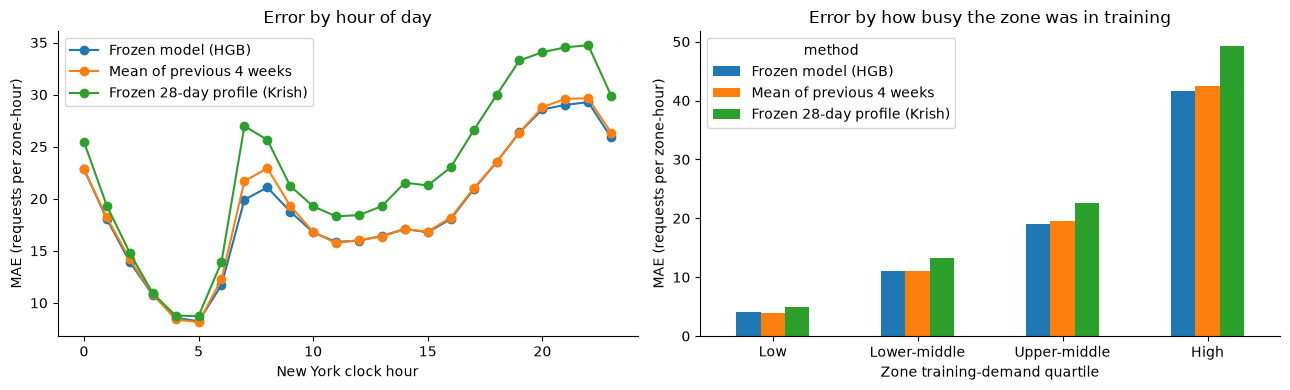

Days on which the frozen model has lower MAE than the 4-week mean: 33 of 61


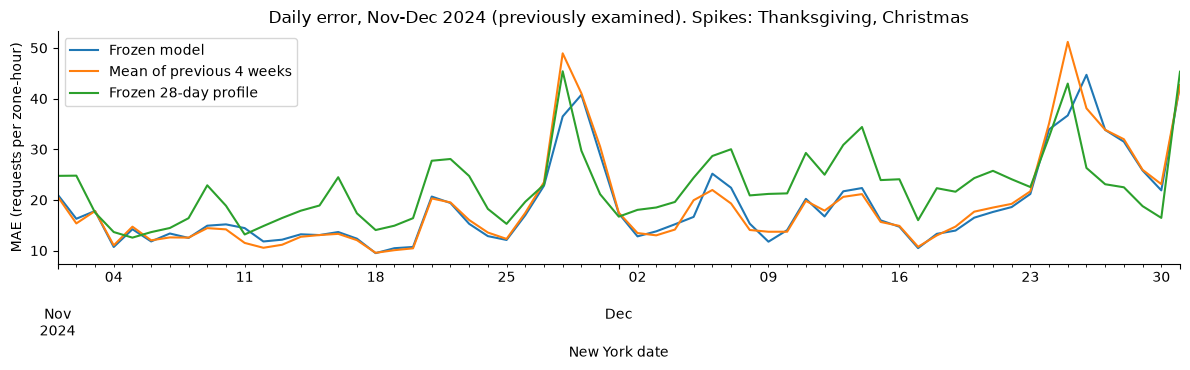

In [13]:
hour_mae = hour_scores.pivot(index="hour_nyc", columns="method", values="MAE")
quartile_mae = breakdowns["training_demand_quartile"].pivot(
    index="training_demand_quartile", columns="method", values="MAE").loc[QUARTILE_LABELS]
shown_methods = ["pred_model", "pred_four_week_mean", "pred_frozen_profile"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for column in shown_methods:
    axes[0].plot(hour_mae.index, hour_mae[column], marker="o", label=METHOD_COLUMNS[column])
axes[0].set(xlabel="New York clock hour", ylabel="MAE (requests per zone-hour)", title="Error by hour of day")
axes[0].legend()
quartile_mae[shown_methods].rename(columns=METHOD_COLUMNS).plot.bar(ax=axes[1], rot=0)
axes[1].set(xlabel="Zone training-demand quartile", ylabel="MAE (requests per zone-hour)",
            title="Error by how busy the zone was in training")
plt.tight_layout()
plt.show()

daily_mae = test_scored.assign(error_model=(test_scored["pred_model"] - test_scored["request_count"]).abs(),
                               error_four_week=(test_scored["pred_four_week_mean"] - test_scored["request_count"]).abs(),
                               error_frozen=(test_scored["pred_frozen_profile"] - test_scored["request_count"]).abs()
                               ).groupby("event_date_nyc")[["error_model", "error_four_week", "error_frozen"]].mean()
daily_mae.columns = ["Frozen model", "Mean of previous 4 weeks", "Frozen 28-day profile"]
days_model_is_better = int((daily_mae["Frozen model"] < daily_mae["Mean of previous 4 weeks"]).sum())
print(f"Days on which the frozen model has lower MAE than the 4-week mean: {days_model_is_better} of {len(daily_mae)}")
daily_mae.plot(figsize=(12, 3.8), ylabel="MAE (requests per zone-hour)", xlabel="New York date",
               title="Daily error, Nov-Dec 2024 (previously examined). Spikes: Thanksgiving, Christmas")
plt.tight_layout()
plt.show()

## Step 12. Which inputs does the frozen model use? (SHAP)

**SHAP** shares each forecast out among the inputs: for every row it says how many requests each input pushed the forecast up or down. We explain a random sample of 5,000 rows from 16-31 October (selection period, not November-December). **Importance is not causation**: SHAP describes how this model uses its inputs, not what would happen if we changed them. Correlated inputs (for example the four lags) split the credit between them. If the model's loss is Poisson, SHAP values are on a log scale (percentage-like effects); otherwise they are in requests.

If the `shap` package could not be loaded in this environment, the cell falls back to scikit-learn's permutation importance (how much MAE grows when one input is shuffled) and says so.

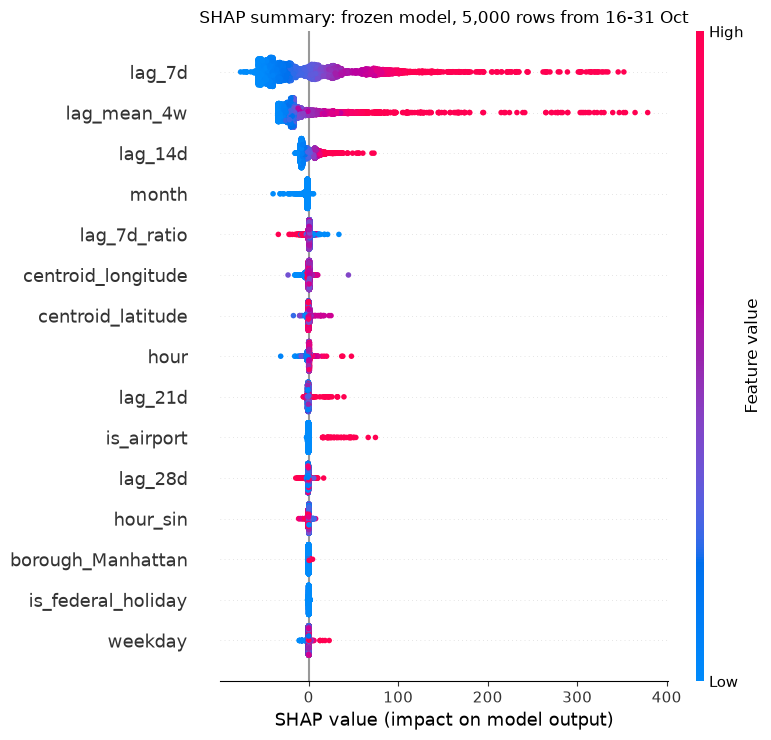

Explanation method used: SHAP (TreeExplainer)


,mean_abs_importance
lag_7d,43.025718
lag_mean_4w,26.791773
lag_14d,7.226870
month,2.184110
lag_7d_ratio,1.338274
centroid_longitude,1.113793
centroid_latitude,0.858947
hour,0.788328
lag_21d,0.744453
is_airport,0.733457


In [14]:
explain_rows = selection_rows.sample(n=SHAP_SAMPLE_ROWS, random_state=RANDOM_SEED)
explain_inputs = explain_rows[FEATURE_COLUMNS]
try:
    import shap
    explanation_method = "SHAP (TreeExplainer)"
    shap_values = shap.TreeExplainer(frozen_model).shap_values(explain_inputs)
    importance = pd.Series(np.abs(shap_values).mean(axis=0), index=FEATURE_COLUMNS)
    shap.summary_plot(shap_values, explain_inputs, show=False, max_display=15)
    plt.title("SHAP summary: frozen model, 5,000 rows from 16-31 Oct")
    plt.tight_layout()
    plt.show()
except ImportError as import_error:
    explanation_method = "permutation importance (shap could not be imported: " + str(import_error) + ")"
    result = permutation_importance(
        frozen_model, explain_inputs, explain_rows["request_count"], scoring="neg_mean_absolute_error",
        n_repeats=PERMUTATION_REPEATS, random_state=RANDOM_SEED)
    importance = pd.Series(result.importances_mean, index=FEATURE_COLUMNS)
    importance.sort_values().tail(15).plot.barh(title="Permutation importance (MAE increase)")
    plt.tight_layout()
    plt.show()
print("Explanation method used:", explanation_method)
importance_table = importance.sort_values(ascending=False).rename("mean_abs_importance").to_frame()
display(importance_table.head(12))

**Reading the plot.** Features at the top matter most to this model. Each dot is one zone-hour; its colour is the input's value and its position left or right shows whether it pushed the forecast down or up. Remember: this explains the model, it does not prove that those inputs cause demand.

## Step 13. Save the forecast file and the summary

`forecast_zone_hour.parquet` has one row per real zone-hour from 2024-10-01 to 2025-01-31 (written with DuckDB). `pred_frozen_profile` is Krish's 28-day profile; the 7-day profile is added as an extra column. A prediction is empty where a baseline cannot be computed. `is_scored_row` is true for the identical rows used for scoring. The summary JSON holds every metric, setting, seed, row count and package version.

In [15]:
real_hours = all_rows[select_dates(all_rows, FORECAST_START, DRIFT_END)]
prediction_columns = CIVIL_KEY + ["pred_model", "pred_last_week", "pred_four_week_mean",
                                  "pred_frozen_profile", "pred_frozen_profile_7d", "is_scored_row"]
forecast_file = real_hours[["zone_id", "hour_start_utc", "event_date_nyc", "hour_nyc",
                            "period_label", "request_count"]].merge(
    forecast_table[prediction_columns], on=CIVIL_KEY, how="left", validate="many_to_one")
forecast_file["event_date_nyc"] = forecast_file["event_date_nyc"].dt.date
print(f"Forecast file rows: {len(forecast_file):,} (source real-hour rows: {len(real_hours):,})")
assert len(forecast_file) == len(real_hours)
assert not forecast_file.duplicated(["zone_id", "hour_start_utc"]).any()
assert forecast_file["pred_model"].notna().all() and (forecast_file["pred_model"] >= 0).all()
assert forecast_file["is_scored_row"].notna().all()

connection.register("forecast_file", forecast_file)
forecast_path = FORECAST_DIR / "forecast_zone_hour.parquet"
connection.execute(f"copy forecast_file to '{forecast_path.as_posix()}' (format parquet)")
check = connection.execute(
    f"select period_label, count(*) rows, count(request_count) actual_known, sum(is_scored_row::int) scored "
    f"from read_parquet('{forecast_path.as_posix()}') group by 1 order by 1").df()
display(check)

Forecast file rows: 776,639 (source real-hour rows: 776,639)


,period_label,rows,actual_known,scored
0,drift,195672,195672,195672.0
1,test,385295,384769,383717.0
2,validation,195672,195672,195672.0


In [16]:
def get_package_version(package_name):
    """Return the installed version of a package, or a clear message if it is missing."""
    try:
        return metadata.version(package_name)
    except metadata.PackageNotFoundError:
        return "not installed"


scored_by_period = check.set_index("period_label")["scored"].astype(int).to_dict()
summary = {
    "created_at_utc": datetime.now(UTC).isoformat(),
    "run_started_utc": RUN_STARTED_UTC.isoformat(),
    "nov_dec_status": "previously examined period, not a pristine test",
    "january_2025_status": "predictions only, never scored, fitted or used for selection",
    "seeds": {"random_seed": RANDOM_SEED},
    "row_counts": {
        "train_rows_used_for_fitting": len(train_rows),
        "september_scoring_rows": len(tuning_rows),
        "oct_1_15_scale_rows": len(calibration_rows),
        "oct_16_31_selection_rows": len(selection_rows),
        "nov_dec_rows": len(test_rows),
        "nov_dec_identical_scored_rows": len(test_scored),
        "forecast_file_rows": len(forecast_file),
        "scored_rows_by_period": scored_by_period,
    },
    "chosen_settings": frozen_choice["chosen_settings"],
    "chosen_candidate": best_candidate,
    "count_bias_scale": count_scale,
    "pred_model_uses_scale": use_scale,
    "best_method_on_oct_16_31": final_method,
    "best_method_column_in_forecast_file": final_method_column,
    "nov_dec_mae_of_method_frozen_on_oct_16_31": float(frozen_choice_mae),
    "nov_dec_days_model_beats_four_week_mean": days_model_is_better,
    "september_scores": tuning_table.reset_index().to_dict(orient="records"),
    "selection_scores_oct_16_31": selection_table.reset_index(names="method").to_dict(orient="records"),
    "nov_dec_overall_scores": overall_scores.reset_index(names="method").to_dict(orient="records"),
    "nov_dec_model_on_all_rows_with_actual": scores_all_known_rows,
    "nov_dec_by_group": {name: scores.to_dict(orient="records") for name, scores in breakdowns.items()},
    "explanation_method": explanation_method,
    "feature_importance_top15": importance_table.head(15)["mean_abs_importance"].to_dict(),
    "package_versions": {name: get_package_version(name) for name in
                         ["scikit-learn", "numpy", "pandas", "duckdb", "shap", "matplotlib", "scipy", "joblib"]},
}
summary_path = FORECAST_DIR / "forecast_summary.json"
summary_path.write_text(json.dumps(summary, indent=2, allow_nan=False), encoding="utf-8")
print("Saved", summary_path.relative_to(REPO_ROOT))
print("Run finished at", datetime.now(UTC).isoformat(), "| started", RUN_STARTED_UTC.isoformat())

Saved data\forecasts\forecast_summary.json
Run finished at 2026-11-15T18:09:51.890728+00:00 | started 2026-11-15T18:09:06.989912+00:00


## Step 14. What this result does and does not say

* The forecast uses only counts at least 7 days old, plus calendar and zone geography, so it can be produced a day (or a week) ahead.
* November-December labels were seen in an older experiment, so those scores are **diagnostic, not a pristine test**. January 2025 was not scored here.
* Forecast accuracy alone does not prove a better fleet placement or more profit; that needs the fleet simulation.
* Weak spots to keep in mind: public holidays, very quiet zones (small counts make percentage errors large) and the busiest zones (large absolute errors).